(example_ro_mean_var_portfolio:title)=
# Robust Mean-Variance Portfolio

This case study will replicate the results of a robust mean-variance portfolio model presented in {cite:ps}`Aps2023mosek` in a more concise and straightforward way. The model is written as

```{math}
\begin{aligned}
\max~&\min\limits_{\pmb{\mu}\in\mathcal{U}}~\pmb{\mu}^{\top}\pmb{x} - \frac{\delta}{2}\pmb{x}^{\top}\pmb{\Sigma}\pmb{x} \\
\text{s.t.}~&\sum\limits_{i=1}^n\pmb{x} = 1 \\
&\pmb{x}\in\mathbb{R}_+^n,
\end{aligned}
```

where the mean returns $\pmb{\mu}$ belongs to the ellipsoidal uncertainty set

```{math}
\mathcal{U} = \left\{
\pmb{\mu}: \left(\pmb{\mu} - \pmb{\mu}_0\right)^{\top}Q^{-1}\left(\pmb{\mu} - \pmb{\mu}_0\right) \leq \gamma^2
\right\},
```

with $Q$ being a known positive semidefinite matrix. 

The nominal mean returns $\pmb{\mu}$ and the covariance matrix $\pmb{\Sigma}$ are estimated based on the [stocks.csv](stocks.csv) dataset, which provides the weekly prices of eight stocks from March 21, 2016 to March 18, 2021. 

In [7]:
import pandas as pd

pd.options.display.precision = 4

data = pd.read_csv('stocks.csv').set_index('Date')
data

,PM,LMT,MCD,MMM,AAPL,MSFT,TXN,CSCO
Date,,,,,,,,
2016-03-14,64.9492,180.0196,102.7192,126.2342,24.2380,47.8760,46.3563,22.2157
2016-03-21,64.5522,177.6482,102.0652,125.5699,24.1808,48.5205,46.0396,21.9256
2016-03-28,66.6844,181.8123,105.1530,127.9139,25.1694,49.7377,47.0465,22.4981
2016-04-04,67.4398,184.4118,105.9312,127.2268,24.8650,48.7084,47.0059,21.7139
2016-04-11,66.9251,184.0125,105.7822,128.8683,25.1373,49.8093,47.8503,22.0786
...,...,...,...,...,...,...,...,...
2021-02-15,72.9401,308.8611,198.4512,156.0663,127.8069,234.6678,165.2999,42.0870
2021-02-22,71.7195,304.1006,192.7475,154.7580,119.3337,226.8236,159.6648,41.3407
2021-03-01,73.5462,315.8780,195.0906,159.8323,119.4911,226.0623,155.6516,42.6121


Following the data preparation steps introduced in the [Mosek Portfolio Optimization Cookbook](https://docs.mosek.com/portfolio-cookbook/inputdata.html), the estimated mean return and covariance matrix can be returned by the `estimate_return()` function, imported from the file [preprocessing.py](preprocessing.py).

In [2]:
from preprocessing import estimate_return

mean, cov = estimate_return(data)

mu0 = mean.values
Sigma = cov.values

We then define the `rmv_portfolio()` function for formulating and solving the robust mean-variance portfolio model. When calling the function, users may specify the estimated mean return `mu0` and estimated covariance matrix `Sigma`, the risk-aversion coefficient `delta`, and the uncertainty parameter `gamma`.

In [3]:
from rsome import ro
from rsome import cpt_solver as cpt
import rsome as rso

def rmv_portfolio(mu0, Sigma, delta, gamma=0, display=False):

    G = np.linalg.cholesky(Sigma)
    Q = G@G.T
    n = len(mu0)

    model = ro.Model()
    x = model.dvar(n)
    r = model.dvar()

    mu = model.rvar(n)
    uset = rso.quad(mu - mu0, np.linalg.inv(Sigma)) <= gamma**2


    if gamma == 0:
        model.max(mu0@x - (delta/2)*r)
    else:
        model.maxmin(mu@x - (delta/2)*r, uset)

    model.st(rso.quad(x, Sigma) <= r)
    model.st(x.sum() == 1, x >= 0)

    model.solve(cpt, display=display)

    risk = r.get()**0.5

    return model.get() + (delta/2)*r.get(), risk, x.get()

Next, the function is executed repeatedly in the following `for`-loop to find out the worst-case returns, the portfolio risks in terms of the standard deviations, and the optimal solutions, under different risk-aversion preference.

In [4]:
import numpy as np

deltas = np.logspace(start=-1, stop=2, num=20)[::-1]

results = pd.DataFrame()
ro_sols = []
nom_sols = []
for i, delta in enumerate(deltas):
    wc_return, risk, xs = rmv_portfolio(mu0, Sigma, delta, gamma=0.02)
    results.loc[i, 'RO Return'] = wc_return
    results.loc[i, 'RO Risk'] = risk
    ro_sols.append(xs)

    wc_return, risk, xs = rmv_portfolio(mu0, Sigma, delta)
    results.loc[i, 'Nominal Return'] = wc_return
    results.loc[i, 'Nominal Risk'] = risk
    nom_sols.append(xs)

ro_sols = np.array(ro_sols)
nom_sols = np.array(nom_sols)

The trade-off between the worst-case mean return and the risk is illustrated by the following figure. 

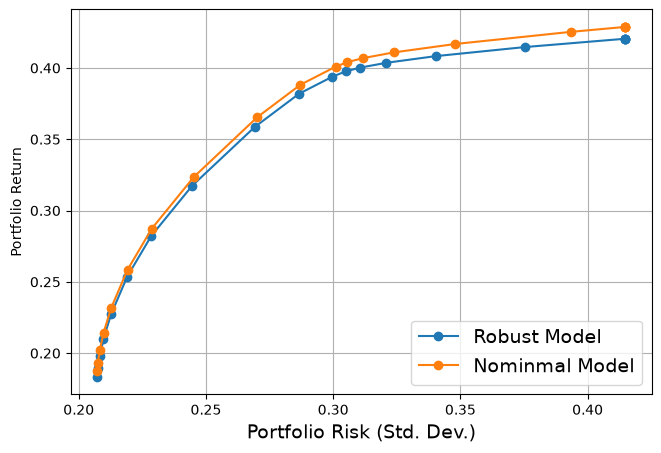

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7.5, 5))
plt.plot(results['RO Risk'], results['RO Return'], marker='o', label='Robust Model')
plt.plot(results['Nominal Risk'], results['Nominal Return'], marker='o', label='Nominmal Model')
plt.legend(fontsize=14)
plt.xlabel('Portfolio Risk (Std. Dev.)', fontsize=14)
plt.ylabel('Portfolio Return')
plt.grid()
plt.show()

Finally, we plot the portfolio allocation $\pmb{x}$ against different portfolio risks as a result of varying the risk-aversion coefficient $\delta$. 

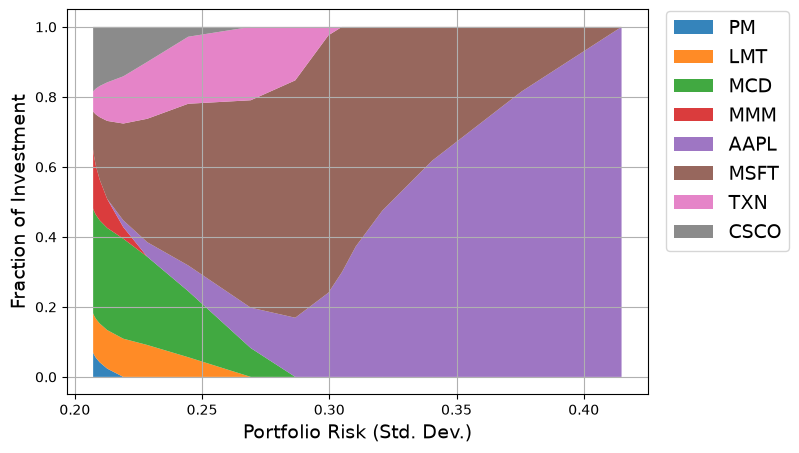

In [6]:
n = data.shape[1]

plt.figure(figsize=(7.5, 5))
bottom = 0
for i in range(n):
    plt.fill_between(results['RO Risk'], bottom, bottom+ro_sols[:, i], 
                     alpha=0.9, 
                     label=data.columns[i])
    bottom += ro_sols[:, i]
    
plt.legend(bbox_to_anchor=(1.26, 1.02), fontsize=14)
plt.xlabel('Portfolio Risk (Std. Dev.)', fontsize=14)
plt.ylabel('Fraction of Investment', fontsize=14)
plt.grid()
plt.show()

Interested readers may refer to the [Mosek Portfolio Optimization Cookbook](https://docs.mosek.com/portfolio-cookbook/factormodels.html#factor-models-example-1) for the similar results.

<br>
<br>

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```